In [67]:
import pandas as pd
import numpy as np

In [68]:
data = pd.read_csv("data_cleaned.csv", low_memory=False)

In [69]:
data["city_slug"] = data["city_slug"].astype("string").str.lower()

In [70]:
data.shape

(782691, 73)

In [71]:
city_classif = pd.read_csv("iran_city_classification.csv")

In [72]:
city_classif.columns = ["name", "city_class"]

In [73]:
city_classif["name"] = city_classif["name"].astype("string").str.lower()

In [74]:
city_classif.dtypes

name          string
city_class       str
dtype: object

In [75]:
columns = city_classif.columns.tolist()
print(columns[0])
print(columns[1])
print(columns) 

name
city_class
['name', 'city_class']


In [76]:
city_classif["name"]

0                karaj
1               tehran
2              mashhad
3                ahvaz
4           kermanshah
            ...       
235              baneh
236    ahmadsar-gourab
237             saqqez
238             mianeh
239         lavandevil
Name: name, Length: 240, dtype: string

In [77]:
print("city_class", city_classif["city_class"].unique())

city_class <ArrowStringArray>
['کلان‌شهر', 'شهر کوچک']
Length: 2, dtype: str


In [78]:
city_classif["city_class"] = city_classif["city_class"].replace({
    "کلان‌شهر": "metro",
    'شهر کوچک': "small_city"
})

In [79]:
print(city_classif["city_class"].unique())

<ArrowStringArray>
['metro', 'small_city']
Length: 2, dtype: str


In [80]:
city_map = city_classif.set_index("name")["city_class"].to_dict()
print(f"cities in reference: {len(city_map)}")

cities in reference: 240


In [81]:
data["city_class"] = data["city_slug"].astype("string").map(city_map)
data["city_class_imputed"] = data["city_class"].isna()
data["city_class"] = data["city_class"].fillna("small_city").astype("category")

In [82]:
print(data["city_class"].value_counts())
data["city_class"].value_counts().sum()

city_class
small_city    419586
metro         363105
Name: count, dtype: int64


np.int64(782691)

In [83]:
unmapped_cities = (
    data.loc[data["city_class_imputed"], "city_slug"]
    .value_counts()
    .head(20)
)
print(unmapped_cities)

city_slug
langarud                1142
andimeshk               1019
garmsar                  658
khoshkbijar              647
bandar-imam-khomeini     642
qorveh                   618
fereydunkenar            535
siahkal                  534
fasa-city                514
takestan                 510
bukan                    488
aligudarz                485
nurabad                  482
dehdasht                 476
norabad                  460
aliabad-katul            394
ardakan                  385
lordegan                 383
koohsar                  382
shaft                    375
Name: count, dtype: int64[pyarrow]


In [84]:
# checking for the houses and not office or shops

residential_cats = [
    "apartment-sell", "apartment-rent",
    "house-villa-sell", "house-villa-rent",
    "villa", "suite-apartment",
]

residential = data[data["cat3_slug"].astype("string").isin(residential_cats)].copy()

print(len(residential))

588594


In [85]:
residential["building_size"] = pd.to_numeric(residential["building_size"], errors="coerce")

In [86]:
residential["building_size"]

0          60.0
1         132.0
3         115.0
5         100.0
6          78.0
          ...  
782685    105.0
782686     50.0
782688    180.0
782689    200.0
782690     70.0
Name: building_size, Length: 588594, dtype: float64

In [87]:
metro_area = residential.loc[residential["city_class"] == "metro", "building_size"].dropna()
small_area = residential.loc[residential["city_class"] == "small_city", "building_size"].dropna()

In [88]:
print(f"metro:      n = {len(metro_area):>7}, mean = {metro_area.mean():>7.1f}, median = {metro_area.median():>7.1f}")
print(f"small_city: n = {len(small_area):>7}, mean = {small_area.mean():>7.1f}, median = {small_area.median():>7.1f}")

metro:      n =  293936, mean =   112.7, median =    97.0
small_city: n =  294624, mean =   119.2, median =   100.0


In [89]:
from scipy.stats import shapiro

rng = np.random.default_rng(42)

metro_sample = rng.choice(
    metro_area, size=min(5000, len(metro_area)), replace=False
)
small_sample = rng.choice(
    small_area, size=min(5000, len(small_area)), replace=False
)

shapiro_metro = shapiro(metro_sample)
shapiro_small = shapiro(small_sample)

print("Shapiro-Wilk on random 5000 per group:")
print(f"metro:      W={shapiro_metro.statistic:.4f}, p={shapiro_metro.pvalue:.2e}")
print(f"small_city: W={shapiro_small.statistic:.4f}, p={shapiro_small.pvalue:.2e}")

Shapiro-Wilk on random 5000 per group:
metro:      W=0.7254, p=1.01e-67
small_city: W=0.6899, p=3.70e-70


<div dir="rtl" align="right">
<p>اگر p-value آزمون Shapiro-Wilk کمتر از ۰.۰۵ باشد، فرض نرمال بودن رد می‌شود. با این حال، چون حجم نمونه بسیار بزرگ است (n > 300,000)، قضیه‌ی حد مرکزی باعث می‌شود آزمون t همچنان معتبر باشد. علاوه بر این، آزمون Mann-Whitney به عنوان آزمون غیرپارامتری نتیجه را تأیید می‌کند.</p>
</div>

<div dir="rtl" align="right">

<h3>فرضیه‌ی صفر و جایگزین</h3>

<ul>
<li><strong>H₀:</strong> میانگین مساحت کلان‌شهرها حداقل برابر شهرهای کوچک است (<code>μ_metro ≥ μ_small_city</code>).</li>
<li><strong>H₁:</strong> میانگین مساحت کلان‌شهرها کمتر است (<code>μ_metro &lt; μ_small_city</code>).</li>
</ul>

<p>اگر <code>p &lt; 0.05</code> باشد، H₀ رد و H₁ پذیرفته می‌شود. آزمون یک‌طرفه است چون صورت مسئله جهت مشخصی داده («کمتر است»).</p>

</div>

<div dir="rtl" align="right">

<h3>اجرای آزمون‌های آماری</h3>
<p>دو آزمون یک‌طرفه اجرا می‌کنیم:</p>
<ul>
<li><strong>Welch t-test</strong> — مقایسه‌ی میانگین دو گروه. فرض برابری واریانس را کنار می‌گذارد.</li>
<li><strong>Mann-Whitney U</strong> — مقایسه‌ی رتبه‌ها. مقاوم به مقادیر پرت.</li>
</ul>
<p>هر دو آزمون جهت فرضیه را در نظر می‌گیرند (کلان‌شهر کوچک‌تر است).</p>

</div>

In [90]:
from scipy.stats import ttest_ind, mannwhitneyu

t_stat, p_one_t = ttest_ind(metro_area, small_area, equal_var=False, alternative="less")
u_stat, p_one_mw = mannwhitneyu(metro_area, small_area, alternative="less")

print(f"Welch t-test  :  t = {t_stat:+.3f},  one-sided p = {p_one_t:.2e}")
print(f"Mann-Whitney  :  U = {u_stat:.0f},  one-sided p = {p_one_mw:.2e}")

Welch t-test  :  t = -33.889,  one-sided p = 8.61e-252
Mann-Whitney  :  U = 41098232494,  one-sided p = 9.78e-251


In [91]:
def cohen_d(x, y):
    nx, ny = len(x), len(y)
    vx, vy = x.var(ddof=1), y.var(ddof=1)
    pooled_sd = np.sqrt(((nx - 1) * vx + (ny - 1) * vy) / (nx + ny - 2))
    return (x.mean() - y.mean()) / pooled_sd

d = cohen_d(metro_area, small_area)
print(f"Cohen's d = {d:.3f}")

Cohen's d = -0.088


<div dir="rtl" align="right">
<p>مقدار Cohen's d برابر با ‎-0.088 است. طبق قاعده‌ی سرانگشتی، ‎|d| < 0.2 به معنای اثر ناچیز است. بنابراین اگرچه اختلاف آماری بسیار معنادار است، اختلاف عملی کوچک است. این نتیجه با برابر نبودن کامل میانه‌ها اما نزدیک بودن آن‌ها (۹۷ در مقابل ۱۰۰) سازگار است.</p>
</div>

<div dir="rtl" align="right">

<h3>آزمون مقاومت — حذف شهرهای پیش‌فرض</h3>
<p>یک نسخه‌ی سخت‌گیرانه می‌سازیم که فقط سطرهایی را نگه می‌دارد که شهرشان در فایل مرجع واقعاً وجود دارد.</p>
<p>اگر نتیجه در هر دو حالت یکسان باشد، فرضیه به‌طور قابل‌اعتماد تأیید یا رد می‌شود.</p>

</div>

In [92]:
strict = residential[~residential["city_class_imputed"]]

In [93]:
metro_strict = strict.loc[strict["city_class"] == "metro", "building_size"].dropna()
small_strict = strict.loc[strict["city_class"] == "small_city", "building_size"].dropna()

<div dir="rtl" align="right">

<h3>مقایسه‌ی دو نسخه — all و strict</h3>
<p>آزمون را روی هر دو نسخه اجرا می‌کنیم و نتایج را کنار هم می‌گذاریم تا ببینیم نتیجه به حضور شهرهای پیش‌فرض حساس است یا نه.</p>

</div>

In [94]:
for name, m, s in [("all", metro_area, small_area), ("strict", metro_strict, small_strict)]:
    t, p1 = ttest_ind(m, s, equal_var=False, alternative="less")
    u, pmw = mannwhitneyu(m, s, alternative="less")
    print(f"{name:>6}:  n_metro={len(m):>6},  n_small={len(s):>6},  "
          f"t={t:+.2f},  p_t={p1:.2e},  p_mw={pmw:.2e}")

   all:  n_metro=293936,  n_small=294624,  t=-33.89,  p_t=8.61e-252,  p_mw=9.78e-251
strict:  n_metro=293936,  n_small=279240,  t=-32.71,  p_t=1.01e-234,  p_mw=3.24e-225


<div dir="rtl" align="right">

<h3>رسم نمودارها</h3>
<ul>
<li>نمودار جعبه‌ای: توزیع مساحت در دو گروه</li>
<li>نمودار میله‌ای: میانگین مساحت در دو گروه</li>
</ul>
<p>مقادیر پرت در جعبه‌ها نمایش داده نمی‌شوند تا خواندن نمودار راحت‌تر باشد.</p>

</div>

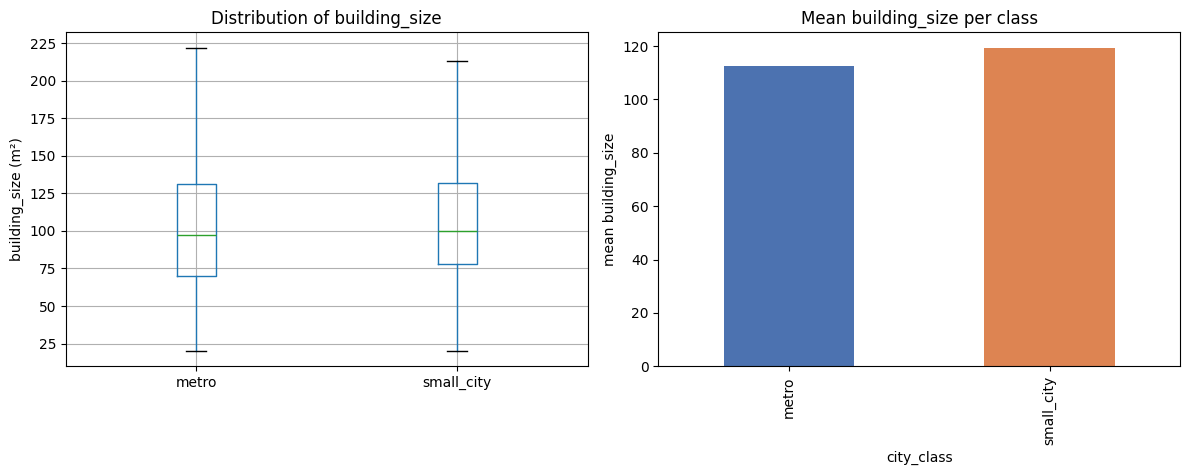

In [95]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

residential.boxplot(
    column="building_size", by="city_class",
    ax=axes[0], showfliers=False,
)
axes[0].set_title("Distribution of building_size")
axes[0].set_xlabel("")
axes[0].set_ylabel("building_size (m²)")

means = residential.groupby("city_class", observed=True)["building_size"].mean()
means.plot(kind="bar", ax=axes[1], color=["#4c72b0", "#dd8452"])
axes[1].set_title("Mean building_size per class")
axes[1].set_ylabel("mean building_size")

plt.suptitle("")
plt.tight_layout()
plt.show()

<div dir="rtl" align="right">

<h3>نتیجه‌گیری نهایی</h3>
<p>سه شرط بررسی می‌شود:</p>
<ol>
<li>جهت اختلاف درست است (<code>t_stat &lt; 0</code>)</li>
<li>t-test معنادار است (<code>p &lt; 0.05</code>)</li>
<li>Mann-Whitney معنادار است (<code>p &lt; 0.05</code>)</li>
</ol>
<p>اگر هر سه برقرار باشند، فرضیه تأیید می‌شود.</p>

</div>

In [96]:
supported = (t_stat < 0) and (p_one_t < 0.05) and (p_one_mw < 0.05)

if supported:
    print("Hypothesis SUPPORTED: metro houses are significantly smaller.")
    print(f"  metro mean      = {metro_area.mean():.1f} m²  (n = {len(metro_area)})")
    print(f"  small city mean = {small_area.mean():.1f} m²  (n = {len(small_area)})")
    print(f"  Welch t-test p  = {p_one_t:.2e}")
    print(f"  Mann-Whitney p  = {p_one_mw:.2e}")
    print(f"  Cohen's d       = {d:.3f}")
else:
    print("Hypothesis NOT supported by the data.")
    print(f"  t-test p = {p_one_t:.2e},  MW p = {p_one_mw:.2e}")

Hypothesis SUPPORTED: metro houses are significantly smaller.
  metro mean      = 112.7 m²  (n = 293936)
  small city mean = 119.2 m²  (n = 294624)
  Welch t-test p  = 8.61e-252
  Mann-Whitney p  = 9.78e-251
  Cohen's d       = -0.088


<div dir="rtl" align="right">

<h3>تفسیر و محدودیت‌ها</h3>

<p><strong>نتیجه:</strong> فرضیه تأیید شد. میانگین مساحت خانه‌های کلان‌شهری ۱۱۲.۷ متر مربع و در شهرهای کوچک ۱۱۹.۲ متر مربع است. هر دو آزمون معناداری بسیار بالایی نشان می‌دهند (p < 10⁻²⁵⁰).</p>

<p><strong>اندازه‌ی اثر:</strong> Cohen's d ≈ -0.088 است که در دسته‌ی اثر ناچیز قرار می‌گیرد. یعنی اختلاف آماری قوی است، اما اختلاف عملی کوچک است. میانه‌ها نیز نزدیک‌اند (۹۷ در مقابل ۱۰۰ متر مربع).</p>

<p><strong>محدودیت‌ها:</strong></p>
<ul>
<li>داده‌ی مرجع فقط دو دسته‌ی <code>metro</code> و <code>small_city</code> دارد؛ بنابراین این آزمون «کلان‌شهر در مقابل شهر کوچک» را بررسی می‌کند، نه روستاها.</li>
<li>شهرهایی که در فایل مرجع نبودند، به‌طور پیش‌فرض <code>small_city</code> در نظر گرفته شدند. نسخه‌ی <code>strict</code> بدون این شهرها نیز اجرا شد و نتیجه تغییر نکرد.</li>
<li>آزمون Shapiro-Wilk روی نمونه‌ی تصادفی نشان داد داده‌ها نرمال نیستند. با این حال، با حجم نمونه‌ی بزرگ (n > 290,000)، قضیه‌ی حد مرکزی آزمون t را معتبر می‌کند و Mann-Whitney نیز نتیجه را تأیید می‌کند.</li>
</ul>

</div>